<a href="https://colab.research.google.com/github/sakshi3121826/Basic-project-data-analysis/blob/main/project3.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
"""
4. Food Delivery Time Analysis (food_delivery.csv, 800 orders)
Question: “What makes deliveries late, and how does delay affect ratings?”

1:Spot the 5 outliers in delivery time with the IQR method in NumPy, then decide whether to remove them.
2:Fill the missing ratings.
3:Create an is_late column for deliveries over 45 minutes.
4:Show delivery time by traffic, weather, and time of day in box plots.
5:Plot distance against delivery time with a regression line.
6:Plot delivery time against rating.
7:Bonus: use np.polyfit to predict delivery time from distance.
"""

In [ ]:
# import the librery
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
# loade the data file
df=pd.read_csv("/content/food_delivery.csv")
df

,order_id,distance_km,prep_time_min,traffic,weather,time_of_day,delivery_time_min,rating
0,5001,6.6,17.0,Low,Clear,Evening,39.0,4.4
1,5002,6.9,18.0,Low,Rain,Evening,50.0,3.9
2,5003,10.1,13.0,High,Clear,Evening,60.0,4.1
3,5004,0.7,15.0,Low,Clear,Evening,10.0,5.0
4,5005,0.9,18.0,Medium,Clear,Afternoon,24.0,4.4
...,...,...,...,...,...,...,...,...
795,5796,0.5,14.0,Medium,Clear,Morning,20.0,5.0
796,5797,8.2,20.0,Low,Clear,Afternoon,57.0,4.2
797,5798,5.4,10.0,Low,Clear,Afternoon,33.0,5.0
798,5799,5.0,15.0,Low,Rain,Evening,36.0,4.8


In [5]:
df.head()
df.isna().sum()

,0
order_id,0
distance_km,0
prep_time_min,0
traffic,0
weather,0
time_of_day,0
delivery_time_min,0
rating,20


In [7]:
# Task1:1:Spot the 5 outliers in delivery time with the IQR method in NumPy,
# then decide whether to remove them.
df
dt=df['delivery_time_min'].to_numpy()
q1,q3=np.percentile(dt,[25,75])
iqr=q3-q1
lower_bound=q1-(1.5*iqr)
upper_bound=q3+(1.5*iqr)
outliers=(dt<lower_bound)|(dt>upper_bound)
print("Bounds:",round(lower_bound,2),round(upper_bound,2))
print("Outliers found:",outliers.sum())
df=df[~outliers].reset_index(drop=True)

Bounds: 1.5 69.5
Outliers found: 27


In [8]:
df

,order_id,distance_km,prep_time_min,traffic,weather,time_of_day,delivery_time_min,rating
0,5001,6.6,17.0,Low,Clear,Evening,39.0,4.4
1,5002,6.9,18.0,Low,Rain,Evening,50.0,3.9
2,5003,10.1,13.0,High,Clear,Evening,60.0,4.1
3,5004,0.7,15.0,Low,Clear,Evening,10.0,5.0
4,5005,0.9,18.0,Medium,Clear,Afternoon,24.0,4.4
...,...,...,...,...,...,...,...,...
768,5796,0.5,14.0,Medium,Clear,Morning,20.0,5.0
769,5797,8.2,20.0,Low,Clear,Afternoon,57.0,4.2
770,5798,5.4,10.0,Low,Clear,Afternoon,33.0,5.0
771,5799,5.0,15.0,Low,Rain,Evening,36.0,4.8


In [11]:
# Task 2 fill the missing ratings
df.isna().sum()
df['rating']=df['rating'].fillna(df['rating'].mean())


In [12]:
df.isna().sum()

,0
order_id,0
distance_km,0
prep_time_min,0
traffic,0
weather,0
time_of_day,0
delivery_time_min,0
rating,0


In [13]:
#3:Create an is_late column for deliveries over 45 minutes.
df['is_late']=np.where(df['delivery_time_min']>45,1,0)
df

,order_id,distance_km,prep_time_min,traffic,weather,time_of_day,delivery_time_min,rating,is_late
0,5001,6.6,17.0,Low,Clear,Evening,39.0,4.4,0
1,5002,6.9,18.0,Low,Rain,Evening,50.0,3.9,1
2,5003,10.1,13.0,High,Clear,Evening,60.0,4.1,1
3,5004,0.7,15.0,Low,Clear,Evening,10.0,5.0,0
4,5005,0.9,18.0,Medium,Clear,Afternoon,24.0,4.4,0
...,...,...,...,...,...,...,...,...,...
768,5796,0.5,14.0,Medium,Clear,Morning,20.0,5.0,0
769,5797,8.2,20.0,Low,Clear,Afternoon,57.0,4.2,1
770,5798,5.4,10.0,Low,Clear,Afternoon,33.0,5.0,0
771,5799,5.0,15.0,Low,Rain,Evening,36.0,4.8,0


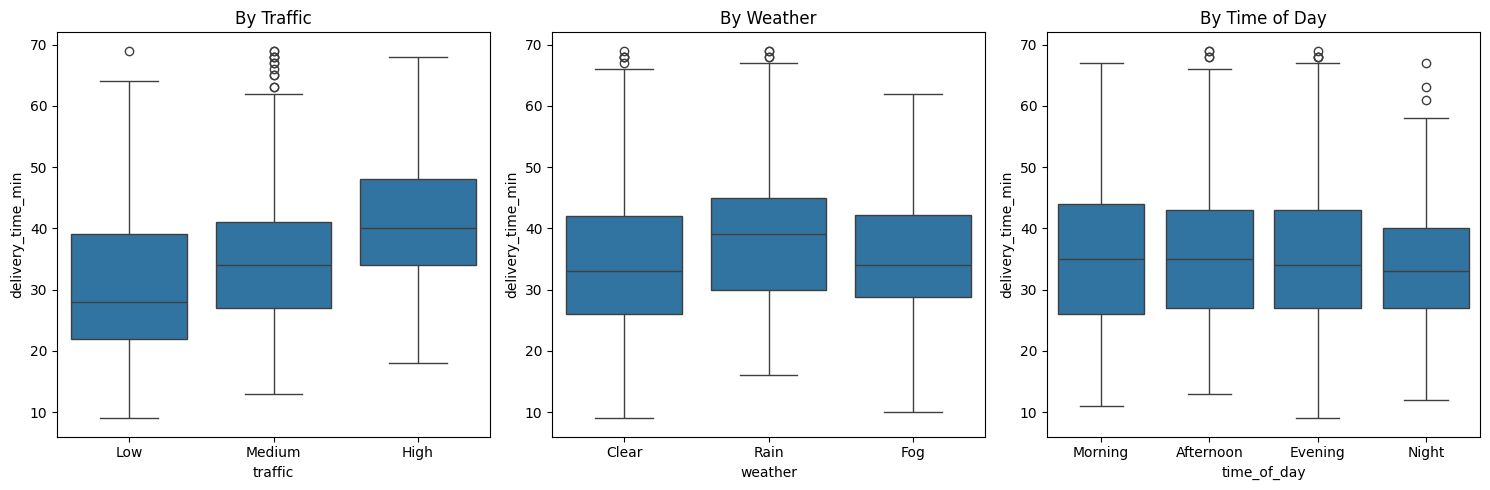

In [16]:
##4:Show delivery time by traffic, weather, and time of day in box plots.
fig,axes=plt.subplots(1,3,figsize=(15,5))
sns.boxplot(data=df,x="traffic",y="delivery_time_min",order=["Low","Medium","High"],ax=axes[0])
axes[0].set_title("By Traffic")
sns.boxplot(data=df,x="weather",y="delivery_time_min",ax=axes[1])
axes[1].set_title("By Weather")
sns.boxplot(data=df,x="time_of_day",y="delivery_time_min",order=["Morning","Afternoon","Evening","Night"],ax=axes[2])
axes[2].set_title("By Time of Day")
plt.tight_layout()
plt.show()

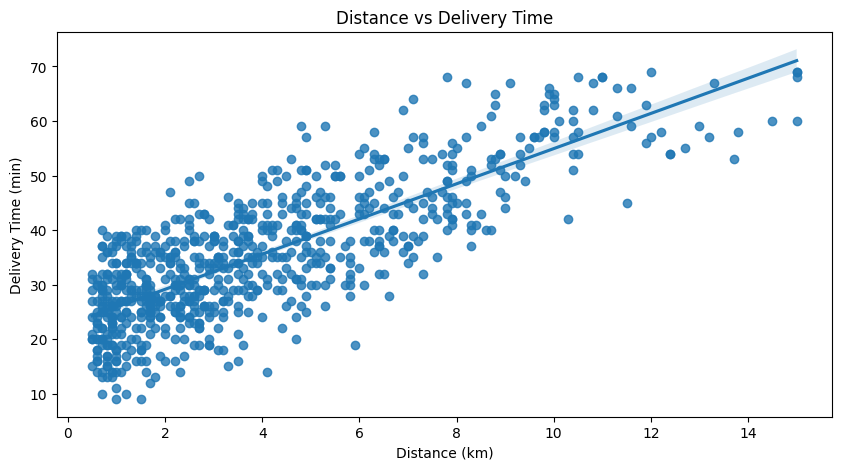

In [17]:
# plot distance against delivery time with a regression line
plt.figure(figsize=(10,5))
sns.regplot(data=df,x='distance_km',y='delivery_time_min')
plt.title("Distance vs Delivery Time")
plt.xlabel("Distance (km)")
plt.ylabel("Delivery Time (min)")
plt.show()

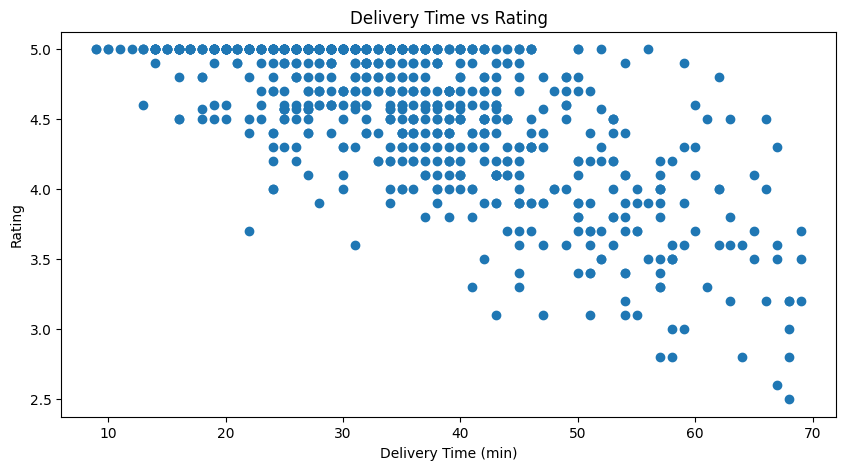

In [18]:
#Plot delivery time against rating
plt.figure(figsize=(10,5))
plt.scatter(df['delivery_time_min'],df['rating'])
plt.xlabel("Delivery Time (min)")
plt.ylabel("Rating")
plt.title("Delivery Time vs Rating")
plt.show()

In [19]:
#Bonus: use np.polyfit to predict delivery time from distance.
x = df["distance_km"]
y = df["delivery_time_min"]
slope, intercept = np.polyfit(x, y, 1)

print("Slope:", slope)
print("Intercept:", intercept)
distance = 5

predicted_time = slope * distance + intercept

print("Predicted Delivery Time:", predicted_time)

Slope: 3.2245577073473726
Intercept: 22.691288657797298
Predicted Delivery Time: 38.814077194534164
